# The toric code in Python: how `toric` computes

The physics is best seen in the [browser app](../app/toric_code_playground.html): click edges and watch the anyons.
This notebook shows how the same calculations are done in Python with `toric`, and why each one is short.

The whole trick is one formula. Every state that Pauli gates can reach from a ground state has the form

$$|\psi\rangle = i^k \, X^a Z^b \, |\text{start}\rangle ,$$

where the bit strings $a$ and $b$ mark the edges that carry an $X$ and a $Z$, and $|\text{start}\rangle$ is a ground
state with 4 logical amplitudes $c$. So a state of a $6 \times 6$ torus (72 qubits) is stored as two lists of edges, a
phase and 4 numbers. Every question below, such as where the anyons are, what the energy is, or what happened to the
stored qubits, is answered by counting bits.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import toric

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.figsize": (5.5, 3.4)})


def amps(s):
    """The 4 logical amplitudes, rounded (all real in this notebook)."""
    return np.round(s.logical().real, 3) + 0.0

## 1. A state is two strings and a phase

`new_state(L)` is a ground state of the $L \times L$ torus: $|00\rangle$, unless you pass another start (`"+0"`,
`"++"`, `"phi+"` or any 4 amplitudes). No gate has been applied yet, so both strings are empty.

In [2]:
s = toric.new_state(6)
t = s.torus                       # the geometry: edge labels, stars, plaquettes, loops
print(s)
print("energy:", s.energy(), "  anyons (e, m):", s.anyons())

PauliState(L=6: 1 * X on [] * Z on [] |start>, start c = [1. 0. 0. 0.])
energy: -72   anyons (e, m): ([], [])


## 2. The ground state is a soup of loops

What does that ground state look like? Write every qubit in the $Z$ basis, $|0\rangle$ or $|1\rangle$, and draw each
$|1\rangle$ edge as a short segment across it. A star $A_v$ flips the 4 edges at a vertex, which draws a small closed
loop around it. Flipping a neighbouring star as well merges the two loops into a bigger one, and flipping many stars
gives a whole soup of loops. `s.sample_picture(rng)` draws one such picture at random, with its amplitude in units of
$2^{-(L^2 - 1)/2}$:

<Axes: title={'center': 'a random picture: amplitude +1'}>

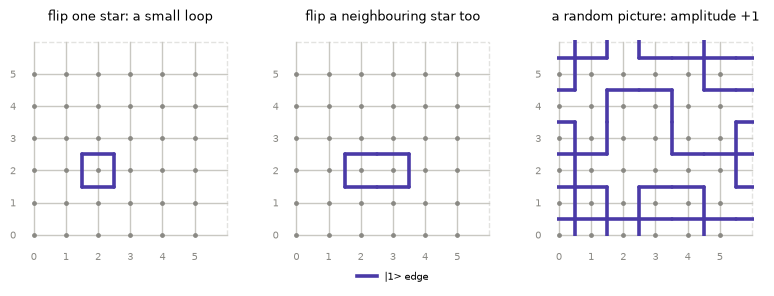

In [3]:
one = np.zeros(t.n_edges, np.uint8)
one[t.star(2, 2)] ^= 1
two = one.copy()
two[t.star(3, 2)] ^= 1
base, config, z, amp = s.sample_picture(np.random.default_rng(1))
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.8))
toric.draw(s, axes[0], "flip one star: a small loop", legend=False, config=one)
toric.draw(s, axes[1], "flip a neighbouring star too", config=two)
toric.draw(s, axes[2], f"a random picture: amplitude {amp.real:+.0f}", legend=False, config=config)

The ground state is the **equal superposition** of all the pictures that star flips can make, $2^{L^2 - 1}$ of them,
all with the same amplitude. (There are $L^2$ stars, but flipping all of them at once flips every edge twice and
changes nothing.) Both kinds of stabilizer are $+1$ on this state:

* **$B_p = +1$.** $B_p$ is $Z$ on the 4 edges of a square, so it gives $-1$ exactly when an odd number of them are
  $|1\rangle$. A closed loop crosses the edges of any square an even number of times, so every picture gives $+1$.
* **$A_v = +1$.** Flipping a star does not change the state; it **reshuffles** the pictures. Each picture becomes
  another picture in the soup, and no two land on the same one. Since every picture has the same amplitude, the sum
  is unchanged. This is the rearrangement theorem of group theory: the pictures form a group under flipping, and
  multiplying every element of a group by one fixed element only permutes the elements.

Star flips never make a loop that wraps around the torus. Adding one such loop gives a second soup, and with loops in
both directions there are 4 soups: the 4 ground states. Section 4 shows that they hold two qubits.

## 3. A gate flips one bit, and the anyons are the ends of the strings

Edges are numbered: `t.h(i, j)` is the horizontal edge leaving vertex $(i, j)$ to the right, and `t.v(i, j)` the
vertical one going up. `s.apply("Z", e)` flips bit $e$ of $b$. A $Z$ anticommutes with the two stars at the ends of
edge $e$, so `toric` flips a flag at each of those two vertices. Those flags are the **e anyons**, and each costs
energy $+2$.

PauliState(L=6: 1 * X on [] * Z on [28] |start>, start c = [1. 0. 0. 0.])
ends of that edge: [(2, 2), (3, 2)]   e anyons: [(2, 2), (3, 2)]   energy: -68


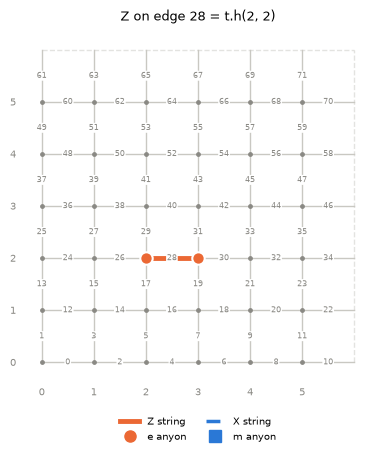

In [4]:
s.apply("Z", t.h(2, 2))
print(s)
print("ends of that edge:", t.ends(t.h(2, 2)), "  e anyons:", s.anyons()[0], "  energy:", s.energy())
toric.draw(s, labels=True, title="Z on edge 28 = t.h(2, 2)");

Now extend the string. Each new $Z$ flips the flag where the string ended, so the anyon leaves, and the flag one step
further on, so it arrives there. A vertex inside the string is touched twice, so its flag is back to normal: **only
the ends of a string are anyons**, and the energy stays the same however long the string is.

PauliState(L=6: 1 * X on [] * Z on [28, 30, 32] |start>, start c = [1. 0. 0. 0.])
e anyons: [(2, 2), (5, 2)]   energy: -68


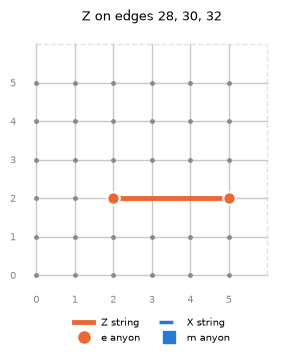

In [5]:
s.apply_string("Z", [t.h(3, 2), t.h(4, 2)])
print(s)
print("e anyons:", s.anyons()[0], "  energy:", s.energy())
toric.draw(s, title="Z on edges 28, 30, 32");

## 4. Strings around the torus are the logical gates

Finish the row so that the string closes around the torus. There are no ends, so no anyons, and the energy is back to
the ground-state value: the state is in the ground space again. But a string that wraps the torus is not a product of
stabilizers, so it need not act as the identity there. On the 4 ground states $|q_1 q_2\rangle$ it acts as a logical
gate. To find which one, `s.windings()` counts how many times the strings cross four fixed reference loops. Each count
is one line of bit counting, for example `s.b[t.x_col(0)].sum() % 2` for $\bar Z_1$, and an odd count means that
logical Pauli was applied.

anyons: ([], [])   energy: -72
windings: {'X1': 0, 'X2': 0, 'Z1': 1, 'Z2': 0}   by hand: 1
logical amplitudes of |00>, |01>, |10>, |11>: [1. 0. 0. 0.]


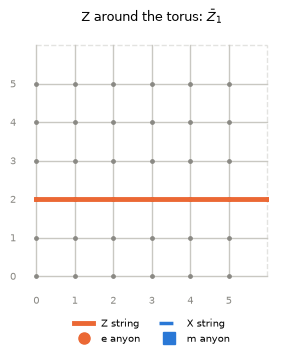

In [6]:
s.apply_string("Z", [t.h(5, 2), t.h(0, 2), t.h(1, 2)])
print("anyons:", s.anyons(), "  energy:", s.energy())
print("windings:", s.windings(), "  by hand:", int(s.b[t.x_col(0)].sum() % 2))
print("logical amplitudes of |00>, |01>, |10>, |11>:", amps(s))
toric.draw(s, title=r"Z around the torus: $\bar Z_1$");

That gate is $\bar Z_1$: a sign on the $q_1 = 1$ part. $|00\rangle$ has no $q_1 = 1$ part, so here $\bar Z_1$ does
nothing, and the amplitudes are still those of $|00\rangle$. Start from $|{+}0\rangle$ instead and the sign shows. Then
an $X$ string around the torus, an m anyon dragged all the way round, flips $q_2$.

Z loop along x:      [ 0.707  0.    -0.707  0.   ]
then X loop along x: [ 0.     0.707  0.    -0.707]  windings: {'X1': 0, 'X2': 1, 'Z1': 1, 'Z2': 0}


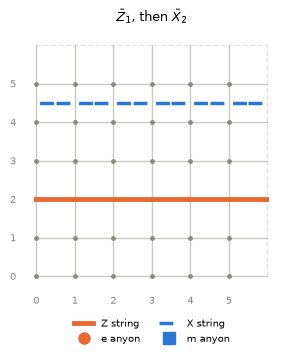

In [7]:
s = toric.new_state(6, "+0")
s.apply_string("Z", t.z_row(2))            # Zbar_1: |+0> -> |-0>
print("Z loop along x:     ", amps(s))
s.apply_string("X", t.x_row(4))            # Xbar_2: flips q2
print("then X loop along x:", amps(s), " windings:", s.windings())
toric.draw(s, title=r"$\bar Z_1$, then $\bar X_2$");

`logical()` works only in the ground space; it raises an error while anyons are present. To *read* a qubit the way an
experiment would, measure a $Z$ loop around the torus: `s.loop_expectation("Zx", row)` for $q_1$ and `"Zy"` for
$q_2$. Below, $q_1 = 1$, so the loop along $x$ gives $-1$. Every row gives the same answer, because moving a loop by
one row multiplies it by plaquettes, which are $+1$.

In [8]:
s = toric.new_state(6)
s.apply_string("X", t.x_col(2))            # Xbar_1: |00> -> |10>
print("<Z loop along x> on rows 0..5:", np.array([s.loop_expectation("Zx", r) for r in range(6)]))
print("<Z loop along y> on cols 0..5:", np.array([s.loop_expectation("Zy", c) for c in range(6)]))

<Z loop along x> on rows 0..5: [-1. -1. -1. -1. -1. -1.]
<Z loop along y> on cols 0..5: [1. 1. 1. 1. 1. 1.]


## 5. Braiding is a sign in the phase $k$

Make an m pair with one $X$, take an e around one of the m's with a small $Z$ loop, then remove the m pair with the
same $X$. Where the $Z$ loop crosses the $X$, on their shared edge, `toric` moves the $Z$ past the $X$, and
$ZX = -XZ$: the phase goes from $i^0$ to $i^2 = -1$. Afterwards only the small closed $Z$ loop remains, which is a
plaquette $B_p = +1$ and does nothing. What survives is the $-1$: the e–m braiding phase.

m pair:           PauliState(L=6: 1 * X on [14] * Z on [] |start>, start c = [1. 0. 0. 0.])
e around one m:   PauliState(L=6: -1 * X on [14] * Z on [14, 15, 17, 26] |start>, start c = [1. 0. 0. 0.])
m pair removed:   PauliState(L=6: -1 * X on [] * Z on [14, 15, 17, 26] |start>, start c = [1. 0. 0. 0.])
logical amplitudes: [-1.  0.  0.  0.]


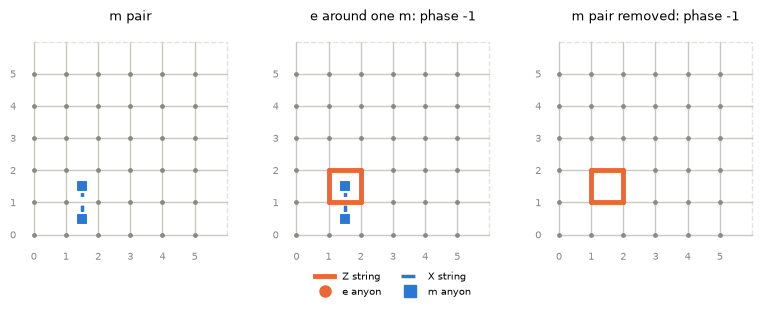

In [9]:
s = toric.new_state(6)
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.8))
s.apply("X", t.h(1, 1))
print("m pair:          ", s)
toric.draw(s, axes[0], "m pair", legend=False)
s.apply_string("Z", t.plaquette(1, 1))
print("e around one m:  ", s)
toric.draw(s, axes[1], "e around one m: phase -1")
s.apply("X", t.h(1, 1))
print("m pair removed:  ", s)
toric.draw(s, axes[2], "m pair removed: phase -1", legend=False)
print("logical amplitudes:", amps(s))

## 6. Heat and error correction, in the same bookkeeping

`thermal_sweep(s, T, rng)` tries, on average, one random $X$ or $Z$ on every edge, and keeps each with probability
$\min(1, e^{-\Delta E/T})$. Creating a pair costs $+4$, while moving or removing anyons is free. Each kept error is one
more bit in $a$ or $b$. `decode(s)` pairs up the closest anyons and joins each pair by a shortest string, which puts
the state back in the ground space. The memory survived if the windings are still all zero.

after 5 sweeps at T = 0.6: 0 X's and 3 Z's,  2 e and 0 m anyons
after decoding: anyons ([], [])   windings {'X1': 0, 'X2': 0, 'Z1': 0, 'Z2': 0}


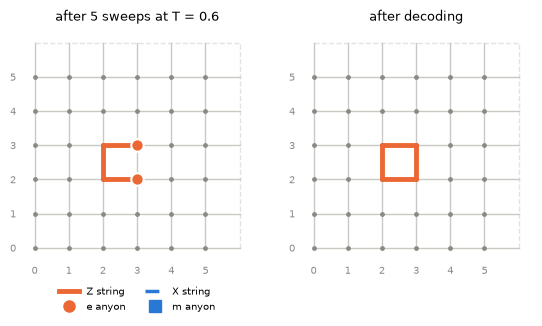

In [10]:
rng = np.random.default_rng(0)
s = toric.new_state(6)
for _ in range(5):
    toric.thermal_sweep(s, 0.6, rng)
e, m = s.anyons()
print(f"after 5 sweeps at T = 0.6: {s.a.sum()} X's and {s.b.sum()} Z's,  {len(e)} e and {len(m)} m anyons")
fig, axes = plt.subplots(1, 2, figsize=(6.6, 3.8))
toric.draw(s, axes[0], "after 5 sweeps at T = 0.6")
toric.decode(s)
print("after decoding: anyons", s.anyons(), "  windings", s.windings())
toric.draw(s, axes[1], "after decoding", legend=False);

`logical_error(s)` asks whether decoding *now* would leave a non-zero winding. `memory_lifetime(L, T, N, ...)`
repeats a sweep, a decode every $N$ sweeps (`None` for never) and that check, and returns the number of sweeps until
the first logical error. Live, 10 runs each on a $6 \times 6$ torus:

In [11]:
for every, label in [(None, "no correction     "), (1, "decode every sweep")]:
    times = [toric.memory_lifetime(6, 0.6, every, 2000, rng) for _ in range(10)]
    print(f"{label}: first logical error after ~{np.mean(times):.0f} sweeps")

no correction     : first logical error after ~15 sweeps


decode every sweep: first logical error after ~215 sweeps


The full run has 200 runs per point (`python scripts/make_results.py memory_lifetimes`, a few minutes on 4 cores).
Without correction a bigger torus does not help: a logical error only ever costs the $+4$ of one pair, whatever $L$
is. With decoding after every sweep, a logical error needs a pair to drift about $L/2$ apart within one sweep, so the
lifetime grows fast with $L$.

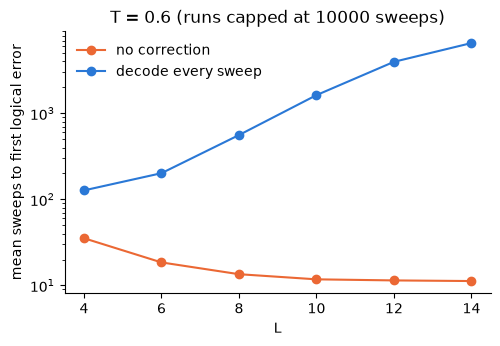

In [12]:
ml = json.loads(Path("../results/memory_lifetimes.json").read_text())
for every, color, label in [(None, ORANGE, "no correction"), (1, BLUE, "decode every sweep")]:
    pts = [p for p in ml["points"] if p["T"] == 0.6 and p["correct_every"] == every]
    plt.semilogy([p["L"] for p in pts], [p["mean"] for p in pts], "o-", color=color, label=label)
plt.xlabel("L")
plt.ylabel("mean sweeps to first logical error")
plt.title(f"T = 0.6 (runs capped at {ml['max_sweeps']} sweeps)")
plt.legend(frameon=False);

## 7. Checked against the full state vector

On a $3 \times 3$ torus (18 qubits), `toric.ExactToricCode` builds the full state vector, $2^{18}$ entries, and applies
the same gates to it directly. The bookkeeping gives the same answers. `tests/test_code.py` checks energies,
stabilizers, amplitudes, loops and logical states this way.

In [13]:
ex = toric.ExactToricCode(3)
s, psi = toric.new_state(3, "+0"), ex.state(toric.START_STATES["+0"])
for gate, e in [("X", ex.torus.h(1, 1))] + [("Z", e) for e in ex.torus.plaquette(1, 1)] + [("X", ex.torus.h(1, 1))]:
    s.apply(gate, e)
    psi = ex.apply(gate, e, psi)
print("toric:", amps(s))
print("exact:", np.round(ex.logical_amplitudes(psi).real, 3) + 0.0)

toric: [-0.707  0.    -0.707  0.   ]
exact: [-0.707  0.    -0.707  0.   ]


## Exercises

1. Make an e pair, then move one e all the way around the torus back to its partner. Has `s.logical()` changed?
   Try again from `toric.new_state(6, "+0")`.
2. Apply $X$ on one edge. Where are the anyons now, and what kind are they (`s.anyons()` returns `(e, m)`)? Draw a
   few pictures as in section 2: where do the loops end?
3. Take an e around an m twice. What is $k$?